# SAMI · Notebook 4 — Can a light classifier reproduce the client's categories?

**Mandate.** MMC labelled part of the chatbot's messages with its own ten categories, and listed the
messages that carry no need of their own (greetings, thanks, "si", a bare place) as a separate sheet;
those become an eleventh class, *Ninguna*, and are part of every result below. This
notebook measures how well a light, cheap classifier reproduces those labels from the pipeline's own
embeddings, and shows the evidence for choosing it. Modules compute (`sami.categorize`), this notebook
consumes.

> **Three rules govern every number below, and all three are enforced in code.**
>
> 1. **One frozen test set.** 20% of the labelled messages are set aside once (seed 42, grouped by message
>    text so a repeated message can never sit on both sides). Every model is scored on it exactly once;
>    choices are made on cross-validation over the remaining 80%.
> 2. **Macro-F1 is the metric.** Documentos has ~880 labelled messages and Emprendimiento ~60; accuracy would
>    reward ignoring the small classes. Accuracy is shown beside it, never instead of it.
> 3. **No message text is printed or saved in this notebook.** Outputs are counts, scores and charts.

The labels are the client's own, **unreviewed**: one annotator, no agreement measured. Section 5 says what
that limits.

In [1]:
import sys, pathlib
# Locate src/ by walking up from the working directory, so `sami` imports whether the kernel starts in
# notebooks/ (JupyterLab) or at the repo root (VS Code).
_cwd = pathlib.Path.cwd()
_src = next((p / "src" for p in (_cwd, *_cwd.parents) if (p / "src" / "sami").is_dir()), None)
if _src is None:
    raise RuntimeError(f"Could not find src/sami/ above {_cwd}. Run this notebook from inside the repository.")
sys.path.insert(0, str(_src))
import warnings
warnings.filterwarnings("ignore")
import time
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.svm import LinearSVC, SVC
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import classification_report, confusion_matrix
from sami import categorize as cz, nlp, theme

ROOT = _src.parent
CACHE = ROOT / "notebooks" / "cache" / "category_embeddings.npz"
SRC = "source: MMC client labels (messages_category_original.xlsx)"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

dev_info = nlp.device_report()
print(f"Compute    : {dev_info['device']} ({dev_info['gpu']}) · torch {dev_info['torch']}")
print(f"Embeddings : {dev_info['embed_model']} @ {dev_info['embed_revision'][:12]}")

Compute    : cpu (None) · torch 2.13.0+cpu
Embeddings : intfloat/multilingual-e5-large @ 3d7cfbdacd47


## 1 · The data and the frozen test set

One row per message of the client's workbook. A message is **labelled** when the client gave it a
`Category 1`, or when it is listed in the `Mensajes_NA` sheet — those are the eleventh class, *Ninguna*.
`Mensajes_NA` has 1,316 rows but only 433 distinct texts ("si" alone is 161 of them), so Ninguna is kept as
**one row per distinct text**; otherwise whichever side of the split "si" fell on would decide the score.

Embeddings are `nlp.embed_documents` — the same pinned multilingual e5-large the pipeline already uses —
computed once and cached (first run ≈ 14 minutes on CPU).

In [2]:
df = cz.load_labeled()
X_all = cz.cached_embeddings(df["text"].tolist(), CACHE)
is_test = cz.frozen_split(df)

lab = df["label"].notna().to_numpy()
y = df["label"].to_numpy()
groups = pd.factorize(cz._norm(df["text"]))[0]
dev_idx = np.flatnonzero(lab & ~is_test.to_numpy())
test_idx = np.flatnonzero(lab & is_test.to_numpy())

# The test set is a property of the data and the seed: it must be the same on every machine.
assert len(test_idx) == 588 and (y[test_idx] != cz.NONE).sum() == 501, "frozen test set changed"
assert not set(groups[dev_idx]) & set(groups[test_idx]), "a message text sits on both sides of the split"

counts = pd.DataFrame({
    "Class": [cz.SHORT[c] for c in cz.CLASSES],
    "Development": [int((y[dev_idx] == c).sum()) for c in cz.CLASSES],
    "Test": [int((y[test_idx] == c).sum()) for c in cz.CLASSES],
}).set_index("Class")
counts["Total"] = counts.sum(axis=1)
print(f"{len(df):,} messages · {lab.sum():,} labelled · {len(dev_idx):,} development / {len(test_idx):,} frozen test")
counts.sort_values("Total", ascending=False)

6,263 messages · 2,932 labelled · 2,344 development / 588 frozen test


,Development,Test,Total
Class,,,
Documentos,701,176,877
Asist. Humanitaria,597,149,746
Ninguna,346,87,433
Servicios,150,38,188
Asilo,148,37,185
Nacionalidad,113,29,142
Empleabilidad,91,22,113
Entidades,62,15,77
Viaje seguro,51,13,64


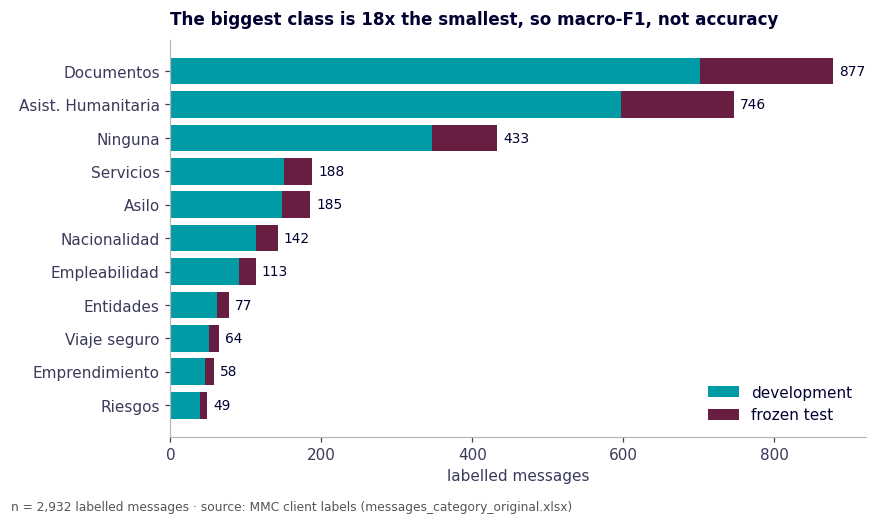

In [3]:
# --- Figure 1: how unbalanced the classes are ---
order = counts.sort_values("Total").index
fig, ax = plt.subplots(figsize=(8, 4.6))
ax.barh(order, counts.loc[order, "Development"], color=theme.TEAL, label="development")
ax.barh(order, counts.loc[order, "Test"], left=counts.loc[order, "Development"], color=theme.WINE, label="frozen test")
for i, c in enumerate(order):
    ax.text(counts.loc[c, "Total"] + 8, i, f"{counts.loc[c, 'Total']:,}", va="center", fontsize=9)
ax.set_xlabel("labelled messages"); ax.legend(frameon=False, loc="lower right")
ax.set_title(f"The biggest class is {counts['Total'].max() / counts['Total'].min():.0f}x the smallest, so macro-F1, not accuracy",
             loc="left", fontsize=11)
fig.text(0.01, -0.02, f"n = {lab.sum():,} labelled messages · {SRC}", fontsize=8, color="#555")
plt.tight_layout(); plt.show()

## 2 · Which algorithm? Eleven classes, frozen embeddings

Given the 1,024-dimensional embedding of a message, which standard classifier recovers the client's label best,
across the ten categories and *Ninguna*? Everything is trained with class weights where the algorithm supports
them. Choice is made on **cross-validation**; the test column is reported once, alongside, and was not used to
choose.

In [4]:
MODELS = {
    "LinearSVC C=2":            lambda: LinearSVC(C=2, class_weight="balanced"),
    "LinearSVC C=1":            lambda: LinearSVC(C=1, class_weight="balanced"),
    "RBF SVM C=5":              lambda: SVC(C=5, class_weight="balanced"),
    "RBF SVM C=10":             lambda: SVC(C=10, class_weight="balanced"),
    "Logistic regression (balanced)": lambda: LogisticRegression(C=10, max_iter=2000, class_weight="balanced"),
    "Logistic regression":      lambda: LogisticRegression(C=10, max_iter=2000),
    "kNN (k=15, cosine)":       lambda: KNeighborsClassifier(15, metric="cosine"),
    "MLP (512)":                lambda: MLPClassifier((512,), alpha=1e-2, early_stopping=True, max_iter=300, random_state=0),
    "Random forest (balanced)": lambda: RandomForestClassifier(500, class_weight="balanced", n_jobs=-1, random_state=0),
}

def compare(models, idx_dev, idx_test, X=X_all):
    rows = []
    for name, make in models.items():
        r = cz.evaluate(make, X, y, groups, idx_dev, idx_test)
        t0 = time.perf_counter(); make().fit(X[idx_dev], y[idx_dev]); sec = time.perf_counter() - t0
        rows.append({"Model": name, "CV macro-F1": r["cv_macro_f1"], "CV sd": r["cv_sd"],
                     "Test macro-F1": r["test_macro_f1"], "Test accuracy": r["test_accuracy"], "Fit (s)": sec})
    return pd.DataFrame(rows).sort_values("CV macro-F1", ascending=False).reset_index(drop=True)

res = compare(MODELS, dev_idx, test_idx)
res.round(3).style.format({"CV sd": "{:.3f}", "CV macro-F1": "{:.3f}", "Test macro-F1": "{:.3f}", "Test accuracy": "{:.1%}", "Fit (s)": "{:.1f}"})

,Model,CV macro-F1,CV sd,Test macro-F1,Test accuracy,Fit (s)
0,LinearSVC C=2,0.735,0.023,0.760,84.2%,2.2
1,RBF SVM C=10,0.734,0.028,0.731,83.2%,1.7
2,RBF SVM C=5,0.733,0.029,0.730,82.3%,2.1
3,LinearSVC C=1,0.732,0.023,0.740,82.3%,2.2
4,Logistic regression (balanced),0.712,0.038,0.737,81.1%,22.1
5,Logistic regression,0.702,0.024,0.676,82.7%,30.3
6,MLP (512),0.672,0.024,0.603,80.8%,15.8
7,Random forest (balanced),0.616,0.038,0.604,78.2%,5.8
8,"kNN (k=15, cosine)",0.575,0.032,0.607,79.4%,0.0


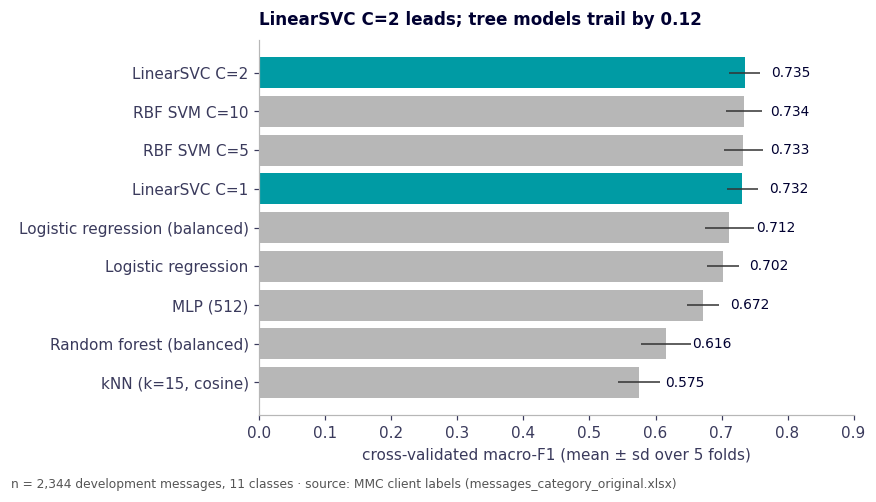

In [5]:
# --- Figure 2: the algorithm comparison ---
r = res.iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 4.4))
ax.barh(r["Model"], r["CV macro-F1"], xerr=r["CV sd"], color=[theme.TEAL if m.startswith("LinearSVC") else theme.GREY for m in r["Model"]],
        error_kw={"ecolor": "#333", "lw": 1})
for i, v in enumerate(r["CV macro-F1"]):
    ax.text(v + 0.04, i, f"{v:.3f}", va="center", fontsize=9)
ax.set_xlim(0, 0.9); ax.set_xlabel("cross-validated macro-F1 (mean ± sd over 5 folds)")
best = res.iloc[0]
ax.set_title(f"{best['Model']} leads; tree models trail by {best['CV macro-F1'] - res.loc[res['Model'].str.startswith('Random'), 'CV macro-F1'].iloc[0]:.2f}",
             loc="left", fontsize=11)
fig.text(0.01, -0.02, f"n = {len(dev_idx):,} development messages, 11 classes · {SRC}", fontsize=8, color="#555")
plt.tight_layout(); plt.show()

**What this says.** On frozen embeddings the *linear* models lead and the tree- and neighbour-based ones trail: with
1,024 dense dimensions and ~2,300 training messages, a linear boundary is hard to beat and random forest (0.12
below LinearSVC) and kNN (0.16 below) have too little to split on. The RBF SVM is within noise of LinearSVC: the
gap (0.001 to 0.002) is far smaller than the fold-to-fold spread (0.023 to 0.029), so there is no evidence for its
extra complexity. The MLP is both lower in cross-validation (0.67) and much worse on the test set (0.60), and
unweighted logistic regression gives up macro-F1 on the small classes (test 0.68 against 0.74 balanced). LinearSVC
has a single hyper-parameter and fits in the time shown in the last column, which is why it is the working choice
below.

## 3 · Can word and character patterns add to the embeddings?

Embeddings capture meaning; TF-IDF over words and characters (fitted on the training folds only) captures
spelling directly, which could help on short, typo-heavy messages. The question is whether adding it improves
on the embeddings alone. The table varies which blocks are used and the regularisation `C`, all on the 11
classes; the top eight rows by cross-validation are shown.

In [6]:
texts = df["text"].to_numpy()
CONFIGS = {                                  # name -> (embedding weight, word n-grams, char n-grams)
    "embeddings only":                 (1.0, False, False),
    "embeddings + words":              (1.0, True, False),
    "embeddings + characters":         (1.0, False, True),
    "embeddings + words + characters": (1.0, True, True),
    "embeddings x2 + words + characters": (2.0, True, True),
    "words + characters only":         (0.0, True, True),
}
rows = []
for name, (w, word, char) in CONFIGS.items():
    feats = lambda tr, te, w=w, word=word, char=char: cz.ngram_features(
        texts[tr], texts[te], X_all[tr], X_all[te], emb_weight=w, word=word, char=char)
    for C_ in (0.5, 1, 2):
        r = cz.evaluate(lambda C_=C_: LinearSVC(C=C_, class_weight="balanced"), feats, y, groups, dev_idx, test_idx)
        rows.append({"Features": name, "C": C_, "CV macro-F1": r["cv_macro_f1"], "CV sd": r["cv_sd"],
                     "Test macro-F1": r["test_macro_f1"], "Test accuracy": r["test_accuracy"]})
ngram = pd.DataFrame(rows).sort_values("CV macro-F1", ascending=False).reset_index(drop=True)
ngram.head(8).round(3).style.format({"CV sd": "{:.3f}", "CV macro-F1": "{:.3f}", "Test macro-F1": "{:.3f}", "Test accuracy": "{:.1%}"})

,Features,C,CV macro-F1,CV sd,Test macro-F1,Test accuracy
0,embeddings only,2.000000,0.735,0.023,0.760,84.2%
1,embeddings only,1.000000,0.732,0.023,0.740,82.3%
2,embeddings only,0.500000,0.728,0.029,0.721,81.1%
3,embeddings + characters,0.500000,0.722,0.032,0.736,82.8%
4,embeddings + characters,1.000000,0.720,0.027,0.747,83.7%
5,embeddings x2 + words + characters,0.500000,0.719,0.023,0.743,83.8%
6,embeddings + characters,2.000000,0.716,0.027,0.745,83.7%
7,embeddings + words + characters,0.500000,0.714,0.036,0.725,82.0%


In [7]:
emb_only = ngram[ngram["Features"] == "embeddings only"].iloc[0]
mixed = ngram[ngram["Features"] != "embeddings only"].iloc[0]
print(f"embeddings only (best C)  : CV {emb_only['CV macro-F1']:.3f} ± {emb_only['CV sd']:.3f} · test {emb_only['Test macro-F1']:.3f}")
print(f"best with n-grams         : CV {mixed['CV macro-F1']:.3f} ± {mixed['CV sd']:.3f} · test {mixed['Test macro-F1']:.3f}  ({mixed['Features']}, C={mixed['C']})")
print(f"difference in CV macro-F1 : {mixed['CV macro-F1'] - emb_only['CV macro-F1']:+.3f}  (fold sd ≈ {emb_only['CV sd']:.3f})")

embeddings only (best C)  : CV 0.735 ± 0.023 · test 0.760
best with n-grams         : CV 0.722 ± 0.032 · test 0.736  (embeddings + characters, C=0.5)
difference in CV macro-F1 : -0.012  (fold sd ≈ 0.023)


**What this says.** Adding word and character n-grams did not help on these labels: the best
combination is below the embeddings alone in cross-validation (difference above, inside the fold spread
either way). The embeddings already carry what the spelling features add, so the extra features buy no
accuracy and cost a more complex model. The working model stays embeddings only.

## 4 · Where the errors are

The working model is LinearSVC (C=2) on the e5 embeddings — simple, a couple of seconds to train, no extra
dependencies. Below: per-class scores on the frozen test set, the confusion matrix, and the most frequent mistakes.

In [8]:
model = MODELS["LinearSVC C=2"]().fit(X_all[dev_idx], y[dev_idx])
pred = model.predict(X_all[test_idx])
rep = pd.DataFrame(classification_report(y[test_idx], pred, labels=list(cz.CLASSES), output_dict=True, zero_division=0)).T
rep = rep.loc[list(cz.CLASSES)].rename(index=cz.SHORT)
rep["support"] = rep["support"].astype(int)
rep.round(2).sort_values("f1-score")

,precision,recall,f1-score,support
Entidades,0.50,0.33,0.40,15
Riesgos,0.50,0.70,0.58,10
Servicios,0.65,0.63,0.64,38
Viaje seguro,0.75,0.69,0.72,13
Empleabilidad,0.85,0.77,0.81,22
Nacionalidad,0.74,0.90,0.81,29
Asilo,0.76,0.92,0.83,37
Asist. Humanitaria,0.88,0.82,0.85,149
Emprendimiento,0.85,0.92,0.88,12
Documentos,0.92,0.88,0.90,176


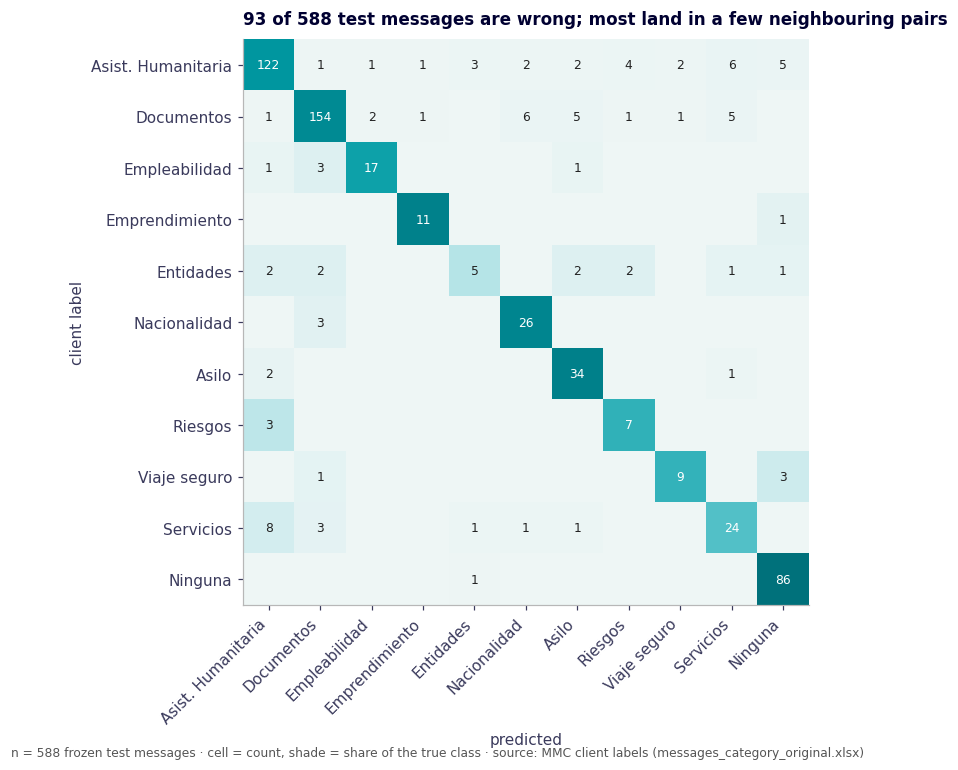

In [9]:
# --- Figure 3: confusion matrix (share of each true class) ---
short = [cz.SHORT[c] for c in cz.CLASSES]
cm = confusion_matrix(y[test_idx], pred, labels=list(cz.CLASSES))
cmn = cm / cm.sum(axis=1, keepdims=True)
fig, ax = plt.subplots(figsize=(8.6, 7))
im = ax.imshow(cmn, cmap=theme.blue_cmap(), vmin=0, vmax=1)
ax.set_xticks(range(len(short)), short, rotation=45, ha="right"); ax.set_yticks(range(len(short)), short)
for i in range(len(short)):
    for j in range(len(short)):
        if cm[i, j]:
            ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=8, color="white" if cmn[i, j] > 0.5 else "#222")
ax.set_xlabel("predicted"); ax.set_ylabel("client label")
errs = int((pred != y[test_idx]).sum())
ax.set_title(f"{errs} of {len(test_idx)} test messages are wrong; most land in a few neighbouring pairs", loc="left", fontsize=11)
fig.text(0.01, 0.01, f"n = {len(test_idx)} frozen test messages · cell = count, shade = share of the true class · {SRC}", fontsize=8, color="#555")
plt.tight_layout(); plt.show()

In [10]:
# The most frequent mistakes, as unordered pairs (a<->b), so a confusion in both directions counts once.
pairs = {}
for t, p in zip(y[test_idx], pred):
    if t != p:
        k = tuple(sorted((cz.SHORT[t], cz.SHORT[p])))
        pairs[k] = pairs.get(k, 0) + 1
top_pairs = pd.Series(pairs).sort_values(ascending=False).head(8)
top_pairs.index = [f"{a}  ↔  {b}" for a, b in top_pairs.index]
top_pairs.rename("errors").to_frame().assign(share=lambda d: (d["errors"] / errs).map("{:.0%}".format))

,errors,share
Asist. Humanitaria ↔ Servicios,14,15%
Documentos ↔ Nacionalidad,9,10%
Documentos ↔ Servicios,8,9%
Asist. Humanitaria ↔ Riesgos,7,8%
Asist. Humanitaria ↔ Entidades,5,5%
Asilo ↔ Documentos,5,5%
Documentos ↔ Empleabilidad,5,5%
Asist. Humanitaria ↔ Ninguna,5,5%


## 5 · What this does and does not show

Computed from the cells above, so the sentences cannot drift from the numbers.

In [11]:
small = rep[(rep["support"] < 15)].index.tolist()
ah_serv = pairs.get(tuple(sorted(("Asist. Humanitaria", "Servicios"))), 0)
doc_serv = pairs.get(tuple(sorted(("Documentos", "Servicios"))), 0)
per = rep.loc[[cz.SHORT[c] for c in cz.CLASSES], "f1-score"]
print(f"Classes with fewer than 15 test messages ({', '.join(small)}): one message moves their F1 by ~0.05-0.1,")
print("  so their individual scores are indicative only; the macro average inherits that noise.")
print(f"Asist. Humanitaria ↔ Servicios: {ah_serv} of {errs} errors · Documentos ↔ Servicios: {doc_serv} of {errs}.")
print(f"Lowest per-class F1: {per.idxmin()} ({per.min():.2f}); highest: {per.idxmax()} ({per.max():.2f}).")
print("Labels are one annotator's, unreviewed: no inter-annotator agreement was measured, so the ceiling this")
print("  classifier could reach is unknown; a pair that is consistently confused may be ambiguous in the labels.")
print(f"Reconciliation: {len(test_idx)} test + {len(dev_idx):,} development = {len(test_idx) + len(dev_idx):,} labelled messages (= {lab.sum():,}).")
assert len(test_idx) + len(dev_idx) == lab.sum()

Classes with fewer than 15 test messages (Emprendimiento, Riesgos, Viaje seguro): one message moves their F1 by ~0.05-0.1,
  so their individual scores are indicative only; the macro average inherits that noise.
Asist. Humanitaria ↔ Servicios: 14 of 93 errors · Documentos ↔ Servicios: 8 of 93.
Lowest per-class F1: Entidades (0.40); highest: Ninguna (0.94).
Labels are one annotator's, unreviewed: no inter-annotator agreement was measured, so the ceiling this
  classifier could reach is unknown; a pair that is consistently confused may be ambiguous in the labels.
Reconciliation: 588 test + 2,344 development = 2,932 labelled messages (= 2,932).


**Reading.**

- A linear classifier on the pipeline's existing embeddings is the right size for this problem: it needs
  nothing beyond what the pipeline already loads, one hyper-parameter, and it leads or ties every other
  algorithm tried on cross-validation (§2). Adding n-gram features did not improve it (§3).
- The errors concentrate in a few neighbouring pairs: the eight most frequent pairs account for 62% of
  them, led by Asistencia Humanitaria ↔ Servicios. Those boundaries are a matter of intent rather than
  topic. This notebook cannot say whether more data or clearer labelling rules would fix them; the pair
  table says where to look first.
- The small classes cannot be judged individually from a test set this size.